# CSV 자료로 댐 시간 유입량 예측하기 — CudaLSTM (hourly)

**이 노트북이 하는 일**

`data/csv/20261008_YDDam_Oper_hourly.csv` 한 파일(시강우 `hrf`, 댐 시간 유입량 `hinflw`)만으로
NeuralHydrology의 `cudalstm` 모델을 학습하고 평가합니다. 공식 튜토리얼(`examples/01-Introduction`)과 같은 API를 쓰되,
CAMELS 같은 공개 데이터셋이 아니라 **직접 가진 csv 파일**을 쓰는 것이 차이점입니다.

| 항목 | 값 |
|---|---|
| 원자료 | `data/csv/20261008_YDDam_Oper_hourly.csv` (2002-01-01 01:00 ~ 2026-01-01 00:00, 1시간 간격) |
| 입력 변수 (`dynamic_inputs`) | `hrf` — 시강우 (mm/h) |
| 목표 변수 (`target_variables`) | `hinflw` — 댐 시간 유입량 (m³/s) |
| 데이터셋 클래스 | `hourlycsv` (`neuralhydrology/datasetzoo/hourlycsv.py`) |
| 모델 | `cudalstm` (hidden_size 64, seq_length 720 시간) |
| 설정 파일 | 같은 폴더의 `YDDam_hourly.yml` |

**진행 순서**

1. 원자료 확인 — 기간, 결측, 이상값, 홍수 사건
2. 전처리 — `hourlycsv` 데이터셋이 기대하는 폴더 구조로 저장
3. 데이터셋 클래스로 읽어 보기 — 모델에 들어가는 샘플 모양 확인
4. 설정 파일(`YDDam_hourly.yml`) 설명
5. 학습 (`start_run`) 과 학습 곡선
6. 평가 (`eval_run`) — 지표, 수문곡선, 홍수 사건 확대, 첨두 분석
7. 정리와 다음 단계

**실행 전 확인**

- 커널: `nh` (이 저장소가 editable 로 설치된 환경). `neuralhydrology.datasetzoo.hourlycsv` 가 import 되어야 합니다.
- GPU 가 있으면 `cuda:0` 으로, 없으면 자동으로 CPU 로 학습합니다 (CPU 에서는 epoch 당 수 분이 걸립니다).
- 노트북은 이 폴더(`examples/07-CSV-Dam-Inflow`)를 작업 디렉터리로 실행해야 합니다. 설정 파일의 경로가 모두 상대 경로이기 때문입니다.

## `hourlycsv` 데이터셋이 기대하는 폴더 구조

NeuralHydrology는 "유역(basin) 하나 = 시계열 파일 하나" 를 전제로 합니다. `hourlycsv` 클래스는 아래 구조에서 **입력 파일과
목표 파일을 따로** 읽은 뒤 시간축으로 합칩니다. 이렇게 나눠 두면 예측(운영) 단계에서 목표 파일이 없어도 입력만으로 예측할 수 있습니다.

```
data/YDDam/                      <- config 의 data_dir
├── time_series/
│   ├── input/hourly/YDDam_input.csv    (date, hrf, ...)      <- dynamic_inputs 로 쓸 컬럼들
│   └── target/hourly/YDDam_target.csv  (date, hinflw, ...)   <- target_variables 로 쓸 컬럼들
└── attributes/*.csv                                        <- (선택) static_attributes 를 쓸 때만
```

- 파일 이름은 basin 파일(`YDDam_basin.txt`)에 적힌 이름과 **정확히** 일치해야 합니다: `YDDam.csv` 또는 `YDDam_input.csv` / `YDDam_target.csv`.
- 변수 이름은 csv 의 **컬럼명 그대로** config 에 적습니다. 별도의 변수 등록 과정이 없습니다.
- 결측은 빈 칸 또는 `NaN` 이어야 합니다. `-999` 같은 값은 결측으로 인식되지 않으므로 전처리에서 바꿔 줘야 합니다.

In [1]:
%matplotlib inline
# Imports
import pickle
import re
import shutil
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from neuralhydrology.datasetzoo import get_dataset
from neuralhydrology.datasetzoo.hourlycsv import load_hourly_input_csv, load_hourly_target_csv
from neuralhydrology.evaluation import metrics
from neuralhydrology.nh_run import eval_run, start_run
from neuralhydrology.utils.config import Config

# 그래프 안의 한글 라벨이 네모(tofu)로 깨지지 않도록 한글 폰트를 지정합니다.
_installed = {f.name for f in matplotlib.font_manager.fontManager.ttflist}
for _font in ("NanumGothic", "NanumBarunGothic", "NanumSquareRound", "NanumGothicCoding", "Noto Sans CJK KR",
              "Malgun Gothic", "AppleGothic"):
    if _font in _installed:
        plt.rcParams["font.family"] = _font
        break
else:
    print("경고: 한글 폰트를 찾지 못했습니다 -- 그래프의 한글이 깨질 수 있습니다.")
plt.rcParams["axes.unicode_minus"] = False

RAW_CSV = Path("../../data/csv/20261008_YDDam_Oper_hourly.csv")  # 원자료
DATA_DIR = Path("../../data/YDDam")  # hourlycsv 레이아웃으로 저장할 위치 (config 의 data_dir 와 같아야 함)
BASIN = "YDDam"  # YDDam_basin.txt 의 내용
EXPERIMENT = "yddam_hourly_cudalstm"  # YDDam_hourly.yml 의 experiment_name

print("GPU 사용 가능:", torch.cuda.is_available())

/home/hydro/miniconda3/envs/nh/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GPU 사용 가능: True


### 보조 함수

run 디렉터리 이름에는 실행 시각이 붙으므로 가장 최근 run 을 자동으로 찾고, `output.log` 에서 epoch 별 검증 결과를 읽어 오는
함수들입니다. `reset_logging()` 은 같은 커널에서 `start_run()` 을 두 번 이상 부를 때 두 번째 run 의 `output.log` 가 비는 문제를 막습니다.

In [2]:
def latest_run_dir(experiment_name: str, runs_dir: Path = Path("runs")) -> Path:
    '''실행할 때마다 날짜/시간이 폴더명에 붙으므로, 가장 최근 run 디렉터리를 자동으로 찾는다.'''
    candidates = sorted(runs_dir.glob(f"{experiment_name}_*"), key=lambda p: p.stat().st_mtime)
    if not candidates:
        raise FileNotFoundError(f"'{experiment_name}'으로 시작하는 run 디렉터리가 {runs_dir} 아래에 없습니다.")
    return candidates[-1]


def validation_history(run_dir: Path) -> pd.DataFrame:
    '''output.log에서 epoch별 검증 loss와 검증 metric을 파싱한다.'''
    line_re = re.compile(r"Epoch (\d+) average validation loss: ([0-9.]+)(.*)")
    metric_re = re.compile(r"(\w[\w\-]*): (-?[0-9.]+)")
    rows = []
    for match in line_re.finditer((run_dir / "output.log").read_text()):
        row = {"epoch": int(match.group(1)), "val_loss": float(match.group(2))}
        row.update({k: float(v) for k, v in metric_re.findall(match.group(3)) if k != "avg_loss"})
        rows.append(row)
    if not rows:
        raise RuntimeError(f"{run_dir / 'output.log'}에서 검증 기록을 찾지 못했습니다.")
    return pd.DataFrame(rows).set_index("epoch")


def best_epoch(run_dir: Path) -> int:
    '''검증 loss가 최소였던 epoch = early stopping이 되돌아갈 '최고 성능' 지점.'''
    return int(validation_history(run_dir)["val_loss"].idxmin())


def completed_run_dir(experiment_name: str, runs_dir: Path = Path("runs")) -> Path | None:
    '''학습이 이미 끝난 run이 있으면 그 디렉터리를, 없으면 None을 돌려준다 (재실행 시 재학습 방지 가드).'''
    if not runs_dir.is_dir():
        return None
    candidates = sorted(runs_dir.glob(f"{experiment_name}_*"), key=lambda p: p.stat().st_mtime, reverse=True)
    for candidate in candidates:
        if not list(candidate.glob("model_epoch*.pt")):
            continue
        try:
            if validation_history(candidate).empty:
                continue
        except (RuntimeError, FileNotFoundError):
            continue
        return candidate
    return None


def reset_logging() -> None:
    '''같은 커널에서 start_run()을 두 번 이상 부르기 전에 호출 (root logger 핸들러 제거).'''
    import logging

    for handler in logging.root.handlers[:]:
        logging.root.removeHandler(handler)
        handler.close()

## 1. 원자료 확인

학습 전에 자료를 눈으로 확인합니다. 특히 (1) 시간 간격이 일정한지, (2) 결측과 이상값이 어디에 있는지, (3) 어떤 홍수 사건이 어느
기간에 들어 있는지를 봐야 학습/검증/테스트 기간을 올바르게 나눌 수 있습니다.

파일 첫 줄의 `date` 앞에는 BOM(`﻿`) 문자가 붙어 있어서 그대로 읽으면 컬럼명이 `'﻿date'` 가 됩니다. `encoding="utf-8-sig"` 로 읽으면 제거됩니다.

In [3]:
raw = pd.read_csv(RAW_CSV, encoding="utf-8-sig", parse_dates=["date"]).set_index("date").sort_index()

print("컬럼          :", list(raw.columns))
print("기간          :", raw.index.min(), "~", raw.index.max())
print("행 수         :", len(raw))
print("시간 간격 분포:", raw.index.to_series().diff().value_counts().head(3).to_dict())
print("중복 시각     :", raw.index.duplicated().sum())
print()
print("결측 개수:")
print(raw.isna().sum().to_string())
print()
print("음수 값 개수:")
print((raw < 0).sum().to_string())
print()
raw.describe().T.round(3)

컬럼          : ['hinflw', 'hrf']
기간          : 2002-01-01 01:00:00 ~ 2026-01-01 00:00:00
행 수         : 210384
시간 간격 분포: {Timedelta('0 days 01:00:00'): 210383}
중복 시각     : 0

결측 개수:
hinflw    11
hrf       39

음수 값 개수:
hinflw    0
hrf       1



,count,mean,std,min,25%,50%,75%,max
hinflw,210373.0,30.386,93.959,0.0,11.283,15.907,24.493,5519.2
hrf,210345.0,0.163,0.978,-5.8,0.000,0.000,0.000,44.9


상위 5개 첨두 유입량:


date
2005-08-03 09:00:00    5519.200
2005-08-03 10:00:00    5472.700
2005-08-03 08:00:00    4849.900
2005-08-03 11:00:00    4831.500
2020-08-07 16:00:00    4394.922


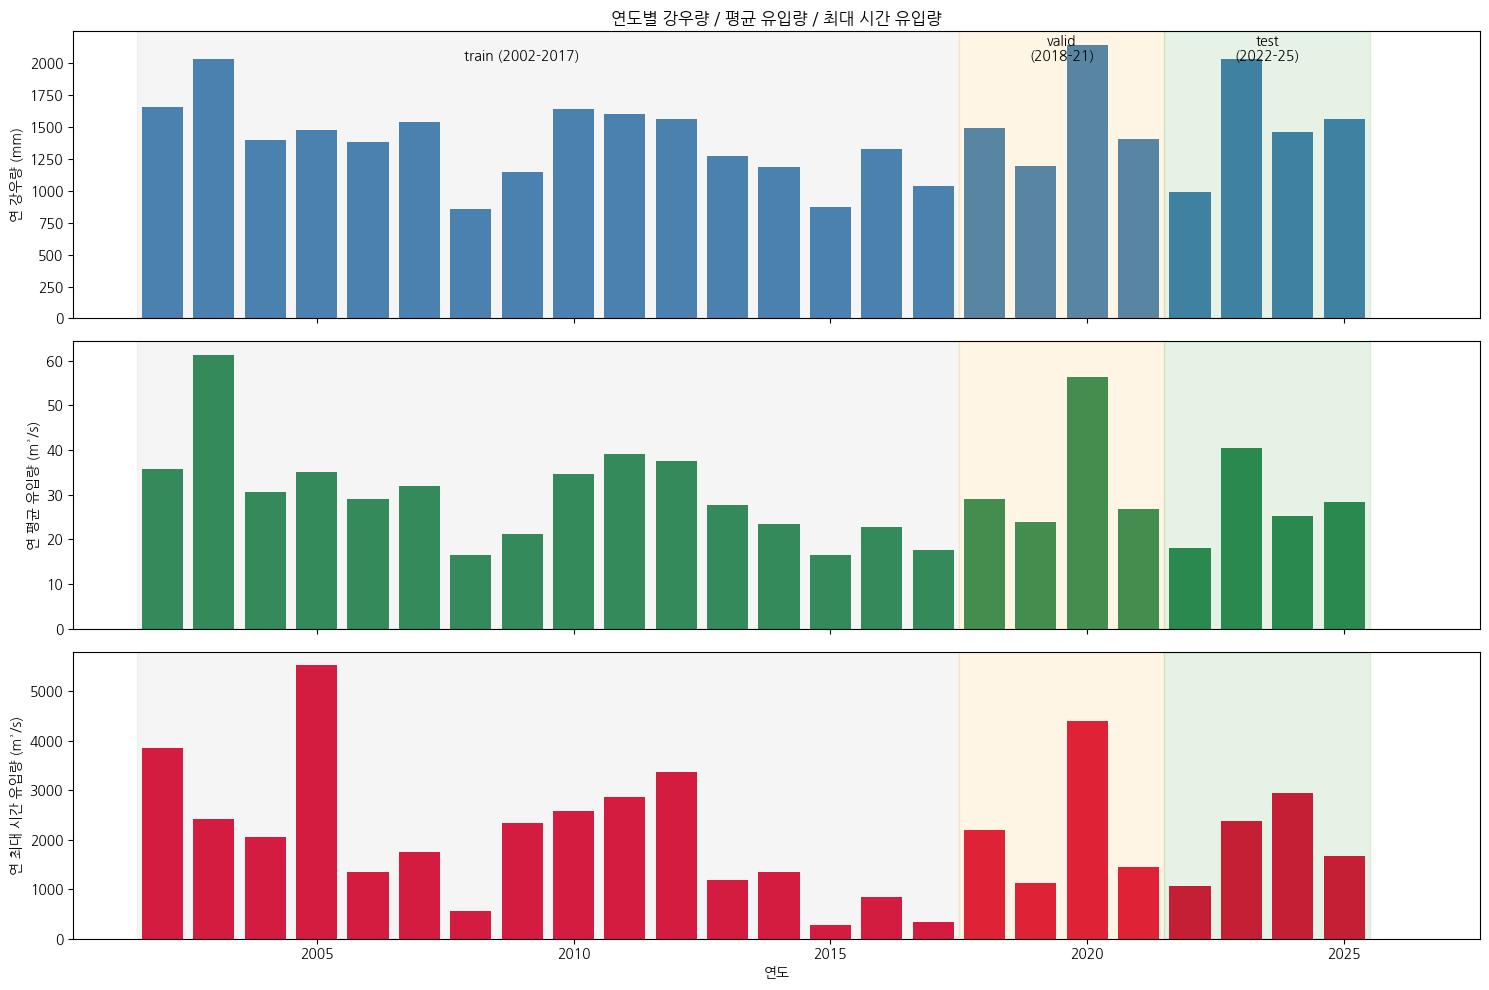

In [4]:
annual = raw.resample("YE").agg(hinflw=("hinflw", "mean"), hrf=("hrf", "sum"), hinflw_max=("hinflw", "max"))
annual.index = annual.index.year

fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)
axes[0].bar(annual.index, annual["hrf"], color="steelblue")
axes[0].set_ylabel("연 강우량 (mm)")
axes[0].set_title("연도별 강우량 / 평균 유입량 / 최대 시간 유입량")
axes[1].bar(annual.index, annual["hinflw"], color="seagreen")
axes[1].set_ylabel("연 평균 유입량 (m³/s)")
axes[2].bar(annual.index, annual["hinflw_max"], color="crimson")
axes[2].set_ylabel("연 최대 시간 유입량 (m³/s)")
for ax in axes:
    ax.axvspan(2001.5, 2017.5, color="gray", alpha=0.08)
    ax.axvspan(2017.5, 2021.5, color="orange", alpha=0.10)
    ax.axvspan(2021.5, 2025.5, color="green", alpha=0.10)
axes[0].text(2009, axes[0].get_ylim()[1] * 0.9, "train (2002-2017)", ha="center")
axes[0].text(2019.5, axes[0].get_ylim()[1] * 0.9, "valid\n(2018-21)", ha="center")
axes[0].text(2023.5, axes[0].get_ylim()[1] * 0.9, "test\n(2022-25)", ha="center")
axes[2].set_xlabel("연도")
fig.tight_layout()

print("상위 5개 첨두 유입량:")
print(raw["hinflw"].nlargest(5).to_string())

### 자료 품질 메모

- **음수 강우 1건** (`hrf = -5.8`): 물리적으로 불가능하므로 전처리에서 결측(`NaN`) 으로 바꿉니다. NeuralHydrology 는 입력에 NaN 이 있는 샘플을
  학습에서 자동으로 제외하므로, 값을 지어내는 것보다 안전합니다.
- **`hinflw = 0` 인 시간이 전체의 약 15%**: 아래 셀에서 보듯 최대 10시간 이내의 짧은 구간이 건기(1~6월)에 흩어져 있습니다.
  댐 유입량은 보통 저수지 수지식으로 역산하는데, 방류량 > 수위 변화분일 때 음수가 되어 0 으로 잘린 흔적으로 보입니다.
  이 노트북에서는 **관측값 그대로** 둡니다(모델은 이 값도 맞추려고 학습합니다). 0 을 결측으로 보는 것이 맞는지는 자료 제공 기관의
  산정 방식을 확인한 뒤 결정하는 것이 좋습니다.
- 마지막 행(2026-01-01 00:00, 모두 0)은 테스트 기간(~2025-12-31) 밖이므로 영향이 없습니다.
- 자료가 2002-01-01 **01:00** 에 시작하므로 00:00 한 시간이 비지만, 데이터셋 클래스가 빈 시각을 NaN 으로 채워 넣습니다.

In [5]:
is_zero = raw["hinflw"] == 0
runs = (is_zero != is_zero.shift()).cumsum()
zero_run_lengths = is_zero.groupby(runs).sum()
zero_run_lengths = zero_run_lengths[zero_run_lengths > 0]

print(f"hinflw == 0 인 시간 비율       : {is_zero.mean():.1%}")
print(f"0 이 연속되는 구간의 최대 길이 : {int(zero_run_lengths.max())} 시간")
print("월별 0 비율:")
print(is_zero.groupby(raw.index.month).mean().round(2).rename("zero_share").to_frame().T.to_string())

hinflw == 0 인 시간 비율       : 15.0%
0 이 연속되는 구간의 최대 길이 : 10 시간
월별 0 비율:
date         1     2     3     4     5     6     7     8     9     10    11    12
zero_share  0.2  0.18  0.15  0.15  0.19  0.23  0.07  0.08  0.09  0.15  0.17  0.17


## 2. 전처리 — `hourlycsv` 레이아웃으로 저장

원자료를 입력 파일과 목표 파일로 나눠 `data/YDDam/` 아래에 저장합니다. 나중에 입력 변수를 늘리고 싶으면
(예: `20261008_YDDam_rf_hourly.csv` 의 관측소별 강우 7개 열) `YDDam_input.csv` 에 열을 추가하고 config 의 `dynamic_inputs` 에 컬럼명을 적기만 하면 됩니다.

In [6]:
clean = raw.copy()
clean.loc[clean["hrf"] < 0, "hrf"] = np.nan  # 음수 강우 -> 결측

input_file = DATA_DIR / "time_series" / "input" / "hourly" / f"{BASIN}_input.csv"
target_file = DATA_DIR / "time_series" / "target" / "hourly" / f"{BASIN}_target.csv"
input_file.parent.mkdir(parents=True, exist_ok=True)
target_file.parent.mkdir(parents=True, exist_ok=True)

clean[["hrf"]].to_csv(input_file)  # 입력: hrf
clean[["hinflw"]].to_csv(target_file)  # 목표: hinflw

print("저장한 파일:")
for f in sorted(DATA_DIR.rglob("*.csv")):
    print(f"  {f.relative_to(DATA_DIR.parent)}  ({f.stat().st_size / 1e6:.1f} MB)")
print()
print("basin 파일 내용:", Path("YDDam_basin.txt").read_text().split())
print()
print(input_file.read_text().splitlines()[:3])
print(target_file.read_text().splitlines()[:3])

저장한 파일:
  YDDam/time_series/input/hourly/YDDam_input.csv  (5.1 MB)
  YDDam/time_series/target/hourly/YDDam_target.csv  (5.5 MB)

basin 파일 내용: ['YDDam']

['date,hrf', '2002-01-01 01:00:00,1.4', '2002-01-01 02:00:00,1.9']
['date,hinflw', '2002-01-01 01:00:00,8.7', '2002-01-01 02:00:00,8.7']


## 3. 데이터셋 클래스로 읽어 보기

학습 코드가 쓰는 것과 같은 함수로 파일이 제대로 읽히는지 확인합니다. `load_hourly_input_csv()` / `load_hourly_target_csv()` 는
`hourlycsv.py` 의 모듈 함수라 데이터셋 클래스 없이도 쓸 수 있습니다.

그다음 실제 `HourlyCSV` 데이터셋 객체를 만들어 **모델에 들어가는 샘플 하나**를 봅니다.

- `x_d['hrf']`: `[seq_length, 1]` = 지난 720시간의 강우 (표준화된 값)
- `y`: `[seq_length, 1]` 의 유입량 중 마지막 `predict_last_n = 1` 개만 손실 계산에 쓰입니다
- 입력 또는 목표에 NaN 이 있는 샘플은 데이터셋 생성 시 자동으로 걸러집니다 (`len(ds)` 가 시간 수보다 작은 이유)

In [7]:
inputs = load_hourly_input_csv(DATA_DIR, BASIN)
targets = load_hourly_target_csv(DATA_DIR, BASIN)
print("입력 컬럼:", list(inputs.columns), "| 기간:", inputs.index.min(), "~", inputs.index.max())
print("목표 컬럼:", list(targets.columns), "| 기간:", targets.index.min(), "~", targets.index.max())

cfg = Config(Path("YDDam_hourly.yml"))
# BaseDataset 은 학습용 데이터셋을 만들 때 feature 별 평균/표준편차(scaler)를 train_dir 에 저장하므로 임시 폴더를 지정합니다.
cfg.train_dir = Path("runs/_dataset_check")
ds = get_dataset(cfg, is_train=True, period="train")

sample = ds[0]
print()
print(f"학습 샘플 수            : {len(ds):,}  (train 기간 시간 수: {len(inputs['2002':'2017']):,})")
print(f"x_d['hrf'] shape        : {tuple(sample['x_d']['hrf'].shape)}  = [seq_length, 1]")
print(f"y shape                 : {tuple(sample['y'].shape)}")
print(f"첫 샘플의 예측 시각     : {sample['date'][-1]}")
print()
print("train 기간 평균/표준편차 (scaler, 입력과 목표 모두 이 값으로 표준화됩니다):")
center = {k: float(v) for k, v in ds.scaler["xarray_feature_center"].items()}
scale = {k: float(v) for k, v in ds.scaler["xarray_feature_scale"].items()}
print(pd.DataFrame({"mean": center, "std": scale}).round(3).to_string())

shutil.rmtree("runs/_dataset_check", ignore_errors=True)
del ds

입력 컬럼: ['hrf'] | 기간: 2002-01-01 01:00:00 ~ 2026-01-01 00:00:00
목표 컬럼: ['hinflw'] | 기간: 2002-01-01 01:00:00 ~ 2026-01-01 00:00:00


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00,  6.47it/s]

100%|██████████| 1/1 [00:00<00:00,  6.44it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:01<00:00,  1.12s/it]

100%|██████████| 1/1 [00:01<00:00,  1.12s/it]



학습 샘플 수            : 129,606  (train 기간 시간 수: 140,255)
x_d['hrf'] shape        : (720, 1)  = [seq_length, 1]
y shape                 : (720, 1)
첫 샘플의 예측 시각     : 2002-01-31T00:00:00.000000

train 기간 평균/표준편차 (scaler, 입력과 목표 모두 이 값으로 표준화됩니다):
          mean     std
hinflw  30.067  88.933
hrf      0.157   0.949


## 4. 설정 파일 (`YDDam_hourly.yml`)

NeuralHydrology 는 코드를 쓰지 않고 YAML 설정만으로 실험을 정의합니다. 핵심 항목과 선택 이유는 다음과 같습니다.

| 항목 | 값 | 이유 |
|---|---|---|
| `dataset` | `hourlycsv` | csv 파일을 그대로 읽는 데이터셋 클래스 |
| `data_dir` | `../../data/YDDam` | 2단계에서 만든 폴더 (노트북 폴더 기준 상대 경로) |
| `forcings` | `hourly` | `hourlycsv` 에서는 선택 사항. `time_series/input/hourly` 아래를 탐색 |
| `dynamic_inputs` | `hrf` | csv 컬럼명 그대로 |
| `target_variables` | `hinflw` | csv 컬럼명 그대로 |
| `clip_targets_to_zero` | `hinflw` | 유입량은 음수가 될 수 없으므로 평가 시 음수 예측을 0 으로 자름 |
| `model` / `hidden_size` | `cudalstm` / 64 | cuDNN LSTM. 단일 유역, 입력 1개라 작은 모델로 충분 |
| `seq_length` | 720 | 30일 선행 강우를 보고 예측. 토양 습윤 상태(선행 조건)를 기억하는 데 필요 |
| `predict_last_n` | 1 | 720시간 창의 마지막 1시간만 손실에 사용 |
| `loss` | `MSE` | 표준화된 목표값의 평균제곱오차. 단일 유역에서는 NSE 손실과 사실상 동일 |
| `epochs` / `early_stopping` | 30 / True (patience 5) | 검증 loss 가 5 epoch 동안 나아지지 않으면 중단. 최소 10 epoch 는 학습 |
| `save_weights_every` | 1 | 모든 epoch 체크포인트 저장 → 검증 loss 최저 epoch 을 골라 평가 |
| 기간 | train 2002-17 / valid 2018-21 / test 2022-25 | 검증·테스트에 각각 큰 홍수(2020, 2023)가 들어가도록 |

주의: `early_stopping: True` 이면 라이브러리가 `ReduceLROnPlateau` 도 함께 켜므로(`Config.dynamic_learning_rate`), `learning_rate` 의 epoch 별 스케줄은 무시되고 epoch 0 의 값만 초기 학습률로 쓰입니다.

In [8]:
print(Path("YDDam_hourly.yml").read_text())

# --- Experiment configurations --------------------------------------------------------------------

# experiment name, used as folder name
experiment_name: yddam_hourly_cudalstm

run_dir:

# files to specify training, validation and test basins (relative to code root or absolute path)
# 유역(댐)이 하나뿐이므로 세 파일이 모두 같은 basin 파일을 가리킵니다.
train_basin_file: YDDam_basin.txt
validation_basin_file: YDDam_basin.txt
test_basin_file: YDDam_basin.txt

# training, validation and test time periods (format = 'dd/mm/yyyy')
# 원자료 기간: 2002-01-01 01:00 ~ 2026-01-01 00:00 (hourly)
#   train      : 2002 ~ 2017 (16년, 2005-08 최대 홍수 포함)
#   validation : 2018 ~ 2021 ( 4년, 2020-08 홍수 포함)  -> early stopping / 최고 epoch 선택
#   test       : 2022 ~ 2025 ( 4년, 2023 홍수 포함)     -> 최종 평가 (학습 중 절대 보지 않음)
train_start_date: "01/01/2002"
train_end_date: "31/12/2017"
validation_start_date: "01/01/2018"
validation_end_date: "31/12/2021"
test_start_date: "01/01/2022"
test_end_date: "31/12/2025"

# fixed seed so that the run is rep

## 5. 학습

`start_run()` 하나로 (1) 데이터셋 생성과 표준화, (2) 모델 생성, (3) epoch 반복, (4) 매 epoch 검증과 체크포인트 저장이 모두 진행됩니다.
결과는 `runs/yddam_hourly_cudalstm_<날짜>_<시각>/` 에 저장됩니다:

- `config.yml` — 실제로 쓰인 전체 설정 (재현용)
- `model_epochNNN.pt` — epoch 별 가중치
- `train_data/train_data_scaler.yml` — 표준화에 쓴 평균/표준편차 (평가 때 그대로 재사용)
- `output.log` — 학습/검증 로그
- `validation/model_epochNNN/validation_metrics.csv` — epoch 별 검증 지표

이미 완료된 run 이 있으면 재학습하지 않습니다. 처음부터 다시 학습하려면 `FORCE_RETRAIN = True` 로 두거나 `runs/` 아래 폴더를 지우세요.

In [9]:
FORCE_RETRAIN = False

existing_run = completed_run_dir(EXPERIMENT)
if existing_run is not None and not FORCE_RETRAIN:
    print(f"이미 완료된 run이 있어 학습을 건너뜁니다: {existing_run}")
else:
    reset_logging()
    if torch.cuda.is_available():
        start_run(config_file=Path("YDDam_hourly.yml"))
    else:
        start_run(config_file=Path("YDDam_hourly.yml"), gpu=-1)

이미 완료된 run이 있어 학습을 건너뜁니다: runs/yddam_hourly_cudalstm_1210_170814


### 학습 곡선과 "최고 epoch"

`epochs: 30` 은 상한이고 실제 종료 시점은 early stopping 이 정합니다. 다만 early stopping 은 **학습을 멈출 뿐 가장 좋았던 가중치로 되돌려 주지 않으므로**,
검증 loss 가 최저였던 epoch 을 직접 찾아 그 체크포인트를 평가합니다. 검증 지표(NSE, KGE)는 2018-2021 검증 기간 전체에 대한 값입니다.

run_dir             : runs/yddam_hourly_cudalstm_1210_170814
학습한 epoch 수      : 25 / 30 (early stopping)
최저 검증 loss epoch : 20  (val_loss=0.08311, NSE=0.908, KGE=0.889)


,val_loss,NSE,KGE
epoch,,,
1,0.3206,0.6503,0.5588
2,0.2394,0.7378,0.6575
3,0.2105,0.7687,0.6867
4,0.1700,0.8118,0.7154
5,0.1378,0.8487,0.7543
6,0.1284,0.8584,0.7632
7,0.1311,0.8560,0.7227
8,0.1080,0.8806,0.8307
9,0.1105,0.8778,0.7708


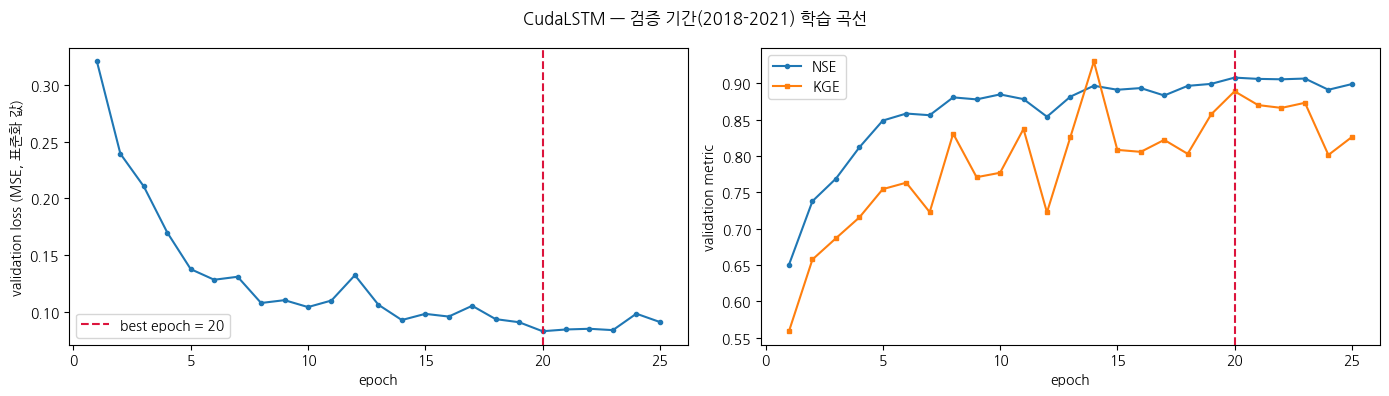

In [10]:
run_dir = latest_run_dir(EXPERIMENT)
history = validation_history(run_dir)
best = best_epoch(run_dir)

print(f"run_dir             : {run_dir}")
print(f"학습한 epoch 수      : {history.index.max()} / 30 (early stopping)")
print(f"최저 검증 loss epoch : {best}  (val_loss={history.loc[best, 'val_loss']:.5f}, "
      f"NSE={history.loc[best, 'NSE']:.3f}, KGE={history.loc[best, 'KGE']:.3f})")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(history.index, history["val_loss"], marker="o", ms=3)
axes[0].axvline(best, color="crimson", ls="--", label=f"best epoch = {best}")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("validation loss (MSE, 표준화 값)")
axes[0].legend()
axes[1].plot(history.index, history["NSE"], marker="o", ms=3, label="NSE")
axes[1].plot(history.index, history["KGE"], marker="s", ms=3, label="KGE")
axes[1].axvline(best, color="crimson", ls="--")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("validation metric")
axes[1].legend()
fig.suptitle("CudaLSTM — 검증 기간(2018-2021) 학습 곡선")
fig.tight_layout()
history.round(4)

## 6. 평가 (테스트 기간 2022-2025)

`eval_run()` 은 지정한 epoch 의 가중치를 불러와 테스트 기간 전체를 예측하고, 결과를 `runs/<run>/test/model_epochNNN/test_results.p` 에 저장합니다.
결과는 유역별 → 주기별(`1h`) → `xarray.Dataset` 구조이고, 변수 이름은 `<target>_obs` / `<target>_sim` 입니다.

In [11]:
eval_run(run_dir=run_dir, period="test", epoch=best)

  0%|          | 0/1 [00:00<?, ?it/s]

# Evaluation:   0%|          | 0/1 [00:00<?, ?it/s]

# Evaluation: 100%|██████████| 1/1 [00:01<00:00,  1.29s/it]

# Evaluation: 100%|██████████| 1/1 [00:01<00:00,  1.29s/it]

In [12]:
with open(run_dir / "test" / f"model_epoch{best:03d}" / "test_results.p", "rb") as fp:
    results = pickle.load(fp)

xr_result = results[BASIN]["1h"]["xr"]
qobs = xr_result["hinflw_obs"].isel(time_step=-1)
qsim = xr_result["hinflw_sim"].isel(time_step=-1)
xr_result

<xarray.Dataset> Size: 561kB
Dimensions:     (date: 35064, time_step: 1)
Coordinates:
  * date        (date) datetime64[us] 281kB 2022-01-01 ... 2025-12-31T23:00:00
  * time_step   (time_step) int64 8B 0
Data variables:
    hinflw_obs  (date, time_step) float32 140kB 15.73 8.412 0.0 ... 6.675 3.494
    hinflw_sim  (date, time_step) float32 140kB 14.03 14.03 ... 14.07 14.07

### 평가 지표

`calculate_all_metrics()` 에 `resolution="1h"` 를 넘겨야 첨두 관련 지표(Peak-Timing, Missed-Peaks)가 시간 해상도로 계산됩니다
(기본값은 `1D` 라서 잊으면 첨두 탐색 창이 24배 넓어집니다).

| 지표 | 의미 | 좋은 값 |
|---|---|---|
| NSE | 관측 평균 대비 모델 설명력. 큰 값(홍수)에 민감 | 1 에 가까울수록 |
| KGE | 상관·변동성·편향을 함께 보는 지표 | 1 에 가까울수록 |
| Alpha-NSE / Beta-NSE | 변동성 비율 / 평균 편향 | 1 / 0 |
| FHV / FLV / FMS | 유량지속곡선의 고유량·저유량·중간 구간 편향(%) | 0 |
| Peak-Timing | 상위 첨두의 시각 오차 평균(시간) | 0 |
| Peak-MAPE | 첨두 크기의 평균 절대 백분율 오차 | 0 |

In [13]:
values = metrics.calculate_all_metrics(qobs, qsim, resolution="1h")
pd.Series(values, name="test (2022-2025)").round(3).to_frame()

/home/hydro/miniconda3/envs/nh/lib/python3.11/site-packages/xarray/core/dataarray.py:6439: FutureWarning: Behaviour of argmin/argmax with neither dim nor axis argument will change to return a dict of indices of each dimension. To get a single, flat index, please use np.argmin(da.data) or np.argmax(da.data) instead of da.argmin() or da.argmax().
  result = self.variable.argmax(dim, axis, keep_attrs, skipna)
/home/hydro/miniconda3/envs/nh/lib/python3.11/site-packages/xarray/core/dataarray.py:6439: FutureWarning: Behaviour of argmin/argmax with neither dim nor axis argument will change to return a dict of indices of each dimension. To get a single, flat index, please use np.argmin(da.data) or np.argmax(da.data) instead of da.argmin() or da.argmax().
  result = self.variable.argmax(dim, axis, keep_attrs, skipna)
/home/hydro/miniconda3/envs/nh/lib/python3.11/site-packages/xarray/core/dataarray.py:6439: FutureWarning: Behaviour of argmin/argmax with neither dim nor axis argument will change 

,test (2022-2025)
NSE,0.889
MSE,856.703
RMSE,29.269
KGE,0.803
Alpha-NSE,1.069
Beta-KGE,1.179
Beta-NSE,0.057
Pearson-r,0.952
FHV,4.641
FMS,-54.941


### 지표 해석 (이 run 의 값 기준, seed 111)

- **NSE ≈ 0.89, Pearson-r ≈ 0.95**: 시강우 한 변수만으로도 시간 유입량의 변동 대부분을 설명합니다. 검증 기간 NSE(≈ 0.91)와 큰 차이가 없어 과적합 징후는 보이지 않습니다.
- **Beta-KGE ≈ 1.18, FLV ≈ 100%**: 평균적으로 유입량을 약 18% 과대 추정하고, 특히 **저유량 구간**을 크게 과대 추정합니다. 관측값의 15% 가 0 인데
  (자료 품질 메모 참고) 모델은 0 을 잘 내지 못하기 때문입니다. 0 의 처리 방식(결측 vs 실제값)을 정하면 이 지표는 크게 달라집니다.
- **FHV ≈ +5%, Peak-Timing ≈ 2.5 h**: 고유량 구간은 거의 편향이 없고, 첨두 시각 오차도 평균 2~3시간으로 양호합니다. 댐 운영 관점에서 가장 중요한 홍수 구간을 잘 맞춥니다.
- **Peak-MAPE ≈ 42%, Missed-Peaks ≈ 0.76**: 작은 첨두까지 포함한 지표라 값이 큽니다. 아래 "홍수 사건별 첨두 분석" 에서 **큰 사건 15개**만 보면 크기 오차 중앙값이 0% 근처,
  ±3시간 안에 맞춘 비율이 80% 이상으로, 큰 사건일수록 정확합니다.
- 연도별로는 **2022년(NSE ≈ 0.55)** 이 가장 낮습니다. 유입량이 가장 적었던 해(연평균 18 m³/s)라 저유량 과대 추정의 영향이 상대적으로 크게 나타난 것입니다.

### 수문곡선 — 테스트 기간 전체와 최대 홍수 사건 확대

위 그림은 4년 전체, 아래 그림은 테스트 기간에서 관측 유입량이 가장 컸던 사건을 전후 10일 범위로 확대한 것입니다.
시간 해상도의 장점은 첨두의 **크기뿐 아니라 발생 시각**까지 비교할 수 있다는 점입니다.

관측 첨두 : 2024-07-10 07:00:00  2,936.9 m³/s
예측 첨두 : 2024-07-10 07:00:00  2,894.3 m³/s  (시각 오차 +0 h, 크기 오차 -1.4%)


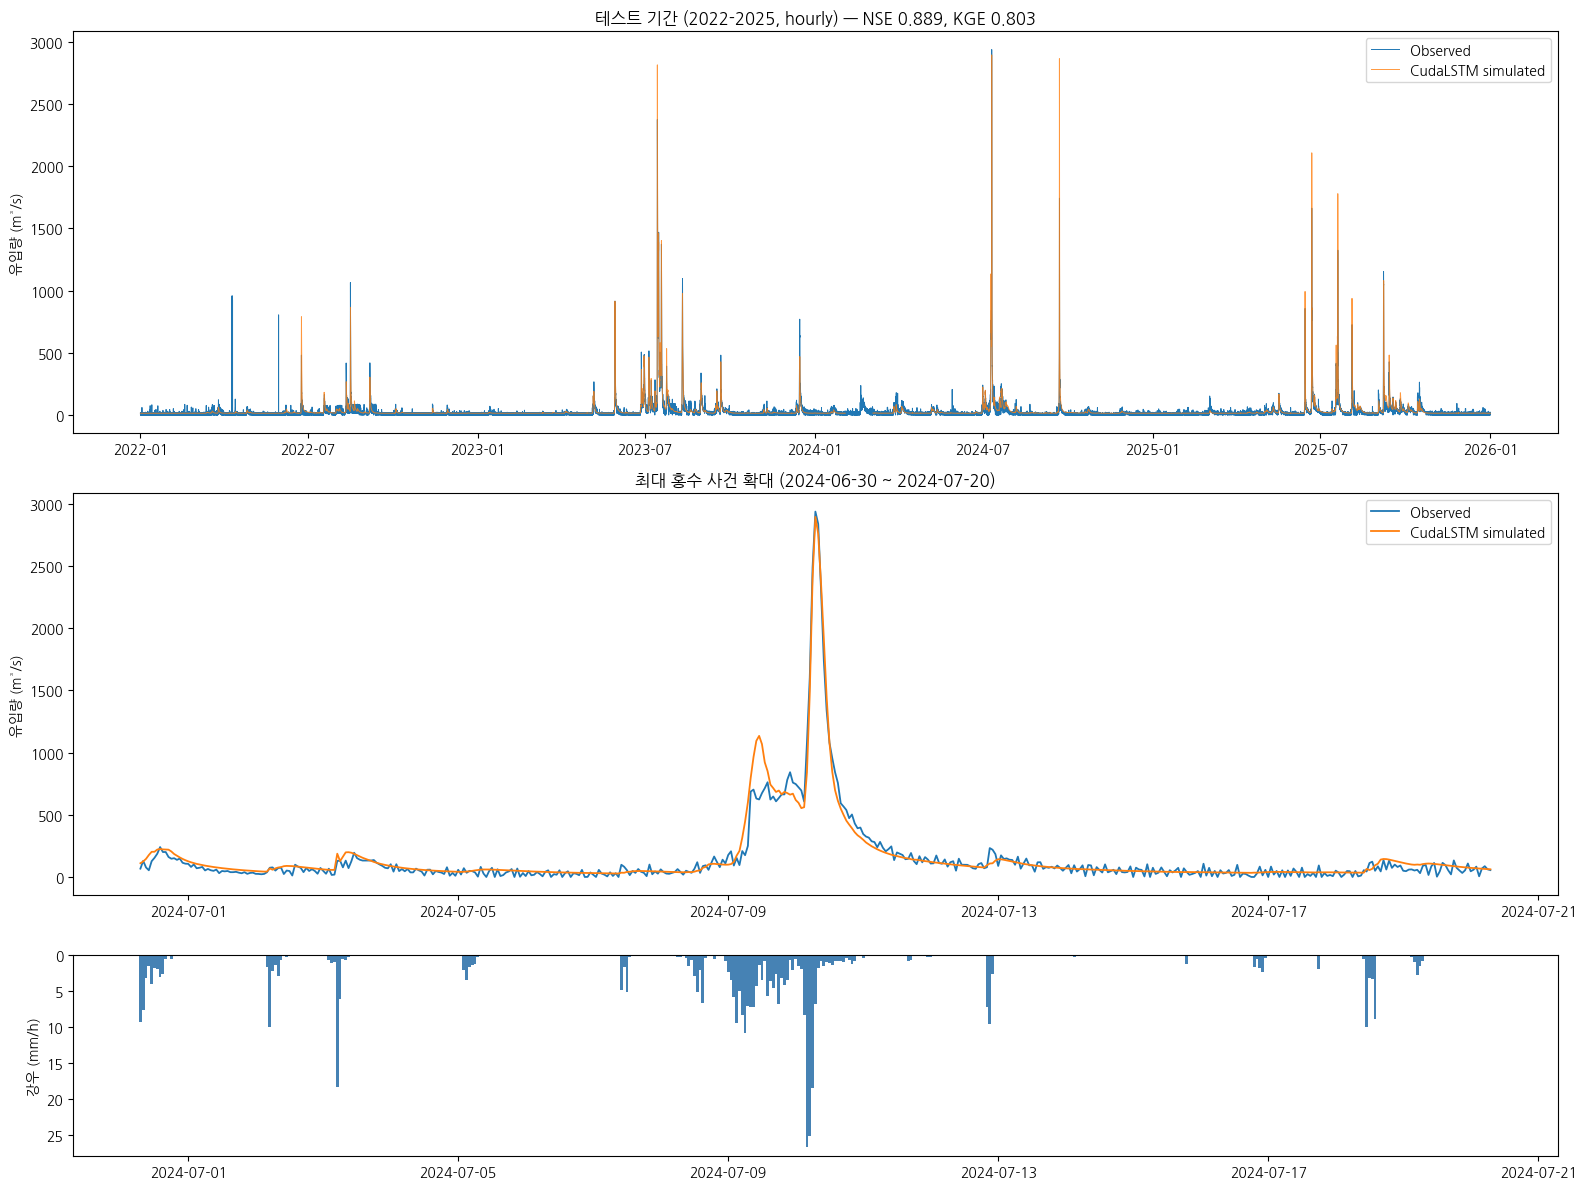

In [14]:
obs_series = qobs.to_series()
sim_series = qsim.to_series()
rain = clean.loc[obs_series.index.min():obs_series.index.max(), "hrf"]

peak_time = obs_series.idxmax()
event = slice(peak_time - pd.Timedelta(days=10), peak_time + pd.Timedelta(days=10))

fig, axes = plt.subplots(3, 1, figsize=(16, 12), gridspec_kw={"height_ratios": [2, 2, 1]})
axes[0].plot(obs_series.index, obs_series, label="Observed", lw=0.7)
axes[0].plot(sim_series.index, sim_series, label="CudaLSTM simulated", lw=0.7, alpha=0.8)
axes[0].set_ylabel("유입량 (m³/s)")
axes[0].set_title(f"테스트 기간 (2022-2025, hourly) — NSE {values['NSE']:.3f}, KGE {values['KGE']:.3f}")
axes[0].legend()

axes[1].plot(obs_series.loc[event].index, obs_series.loc[event], label="Observed", lw=1.3)
axes[1].plot(sim_series.loc[event].index, sim_series.loc[event], label="CudaLSTM simulated", lw=1.3)
axes[1].set_ylabel("유입량 (m³/s)")
axes[1].set_title(f"최대 홍수 사건 확대 ({event.start.date()} ~ {event.stop.date()})")
axes[1].legend()

axes[2].bar(rain.loc[event].index, rain.loc[event], width=1 / 24, color="steelblue")
axes[2].set_ylabel("강우 (mm/h)")
axes[2].invert_yaxis()
axes[2].set_xlim(axes[1].get_xlim())
fig.tight_layout()

sim_event = sim_series.loc[event]
print(f"관측 첨두 : {peak_time}  {obs_series.max():,.1f} m³/s")
print(f"예측 첨두 : {sim_event.idxmax()}  {sim_event.max():,.1f} m³/s  "
      f"(시각 오차 {(sim_event.idxmax() - peak_time).total_seconds() / 3600:+.0f} h, "
      f"크기 오차 {(sim_event.max() / obs_series.max() - 1):+.1%})")

### 홍수 사건별 첨두 분석

테스트 기간에서 관측 유입량 상위 시점을 서로 72시간 이상 떨어지도록 골라 독립적인 홍수 사건 15개로 보고, 사건마다
첨두 **시각 오차**(예측 첨두 − 관측 첨두, 시간)와 **크기 오차**(%)를 계산합니다. 댐 운영에서는 평균적인 적합도(NSE)보다 이 두 값이 더 직접적인 관심사입니다.

첨두 시각을 ±3시간 안에 맞춘 사건 비율 : 87%
첨두 크기 오차의 중앙값                : -0.0%


,관측 첨두 (m³/s),예측 첨두 (m³/s),시각 오차 (h),크기 오차 (%)
관측 첨두 시각,,,,
2022-04-10 06:00:00,958.900024,14.300000,-24.0,-98.500000
2022-05-30 13:00:00,804.799988,14.900000,-5.0,-98.099998
2022-08-16 07:00:00,1064.699951,865.700012,2.0,-18.700001
2023-05-29 14:00:00,915.099976,914.700012,0.0,-0.000000
2023-07-14 11:00:00,2375.100098,2813.899902,0.0,18.500000
2023-07-18 20:00:00,1372.699951,1401.699951,1.0,2.100000
2023-08-10 16:00:00,1097.699951,977.299988,-1.0,-11.000000
2023-12-15 13:00:00,769.900024,469.500000,1.0,-39.000000
2024-07-10 07:00:00,2936.899902,2894.300049,0.0,-1.400000


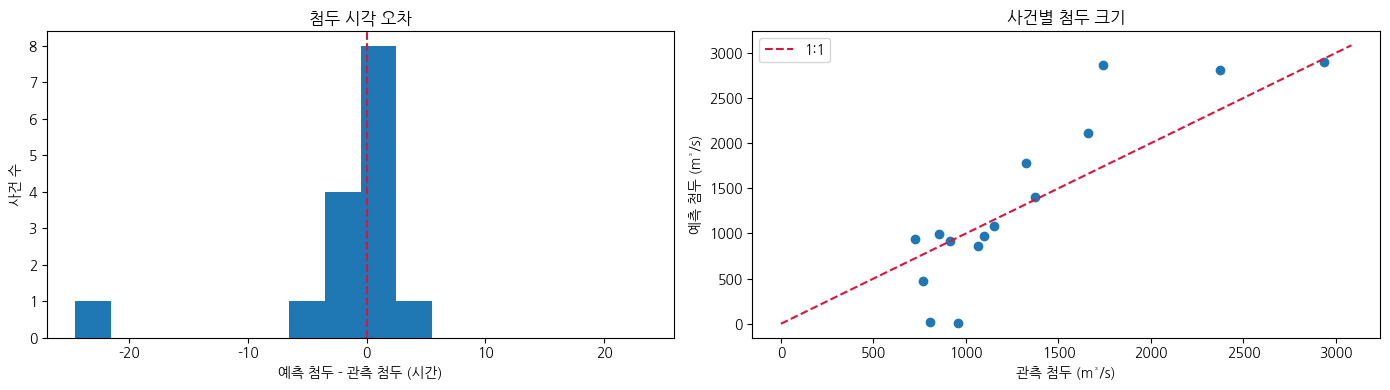

In [15]:
events, candidates = [], obs_series.dropna().sort_values(ascending=False)
for timestamp in candidates.index:
    if all(abs((timestamp - e).total_seconds()) > 72 * 3600 for e in events):
        events.append(timestamp)
    if len(events) == 15:
        break

rows = []
for peak in sorted(events):
    window = slice(peak - pd.Timedelta("24h"), peak + pd.Timedelta("24h"))
    sim_window = sim_series.loc[window]
    if sim_window.isna().all():
        continue
    rows.append({
        "관측 첨두 시각": peak,
        "관측 첨두 (m³/s)": obs_series[peak],
        "예측 첨두 (m³/s)": sim_window.max(),
        "시각 오차 (h)": (sim_window.idxmax() - peak).total_seconds() / 3600,
        "크기 오차 (%)": (sim_window.max() / obs_series[peak] - 1) * 100,
    })
peaks = pd.DataFrame(rows).set_index("관측 첨두 시각")

print(f"첨두 시각을 ±3시간 안에 맞춘 사건 비율 : {(peaks['시각 오차 (h)'].abs() <= 3).mean():.0%}")
print(f"첨두 크기 오차의 중앙값                : {peaks['크기 오차 (%)'].median():+.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(peaks["시각 오차 (h)"], bins=np.arange(-24.5, 25.5, 3))
axes[0].axvline(0, color="crimson", ls="--")
axes[0].set_xlabel("예측 첨두 - 관측 첨두 (시간)")
axes[0].set_ylabel("사건 수")
axes[0].set_title("첨두 시각 오차")
axes[1].scatter(peaks["관측 첨두 (m³/s)"], peaks["예측 첨두 (m³/s)"])
lim = [0, max(peaks["관측 첨두 (m³/s)"].max(), peaks["예측 첨두 (m³/s)"].max()) * 1.05]
axes[1].plot(lim, lim, color="crimson", ls="--", label="1:1")
axes[1].set_xlabel("관측 첨두 (m³/s)")
axes[1].set_ylabel("예측 첨두 (m³/s)")
axes[1].set_title("사건별 첨두 크기")
axes[1].legend()
fig.tight_layout()
peaks.round(1)

### 연도별 성능과 산점도

연도별 NSE 는 특정 해(예: 큰 홍수가 있던 2023년)에 성능이 쏠려 있는지 보여 줍니다. 산점도는 로그 축으로 그려 저유량 구간의 거동도 함께 봅니다.

,NSE,KGE,obs_mean,sim_mean,obs_max,sim_max
year,,,,,,
2022,0.552,0.651,18.111000,21.893,1064.739990,865.711975
2023,0.954,0.918,40.473000,43.646,2375.142090,2813.940918
2024,0.843,0.685,25.146999,31.021,2936.854004,2894.319092
2025,0.876,0.725,28.462000,35.111,1662.472046,2107.006104


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


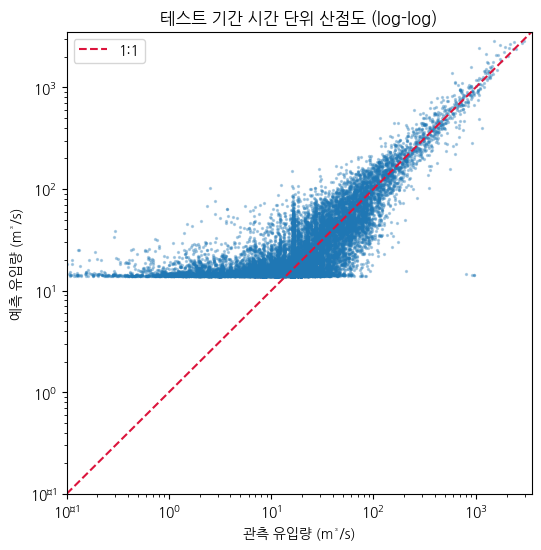

In [16]:
yearly = []
for year, obs_y in obs_series.groupby(obs_series.index.year):
    sim_y = sim_series.loc[obs_y.index]
    yearly.append({
        "year": year,
        "NSE": metrics.nse(qobs.sel(date=str(year)), qsim.sel(date=str(year))),
        "KGE": metrics.kge(qobs.sel(date=str(year)), qsim.sel(date=str(year))),
        "obs_mean": obs_y.mean(),
        "sim_mean": sim_y.mean(),
        "obs_max": obs_y.max(),
        "sim_max": sim_y.max(),
    })
yearly = pd.DataFrame(yearly).set_index("year")

mask = obs_series.notna() & sim_series.notna()
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(obs_series[mask], sim_series[mask], s=2, alpha=0.3)
lim = [0.1, max(obs_series.max(), sim_series.max()) * 1.2]
ax.plot(lim, lim, color="crimson", ls="--", label="1:1")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel("관측 유입량 (m³/s)")
ax.set_ylabel("예측 유입량 (m³/s)")
ax.set_title("테스트 기간 시간 단위 산점도 (log-log)")
ax.legend()
yearly.round(3)

In [17]:
# 다른 노트북/스크립트에서 비교할 수 있도록 결과 요약을 저장
summary = {
    "model": "cudalstm",
    "notebook": "examples/07-CSV-Dam-Inflow/YDDam_hourly.ipynb",
    "run_dir": str(run_dir),
    "trained_epochs": int(history.index.max()),
    "best_epoch": int(best),
    "best_val_loss": float(history.loc[best, "val_loss"]),
    **{k: float(v) for k, v in values.items()},
}
pd.Series(summary).to_json("hourly_summary.json")
summary

{'model': 'cudalstm',
 'notebook': 'examples/07-CSV-Dam-Inflow/YDDam_hourly.ipynb',
 'run_dir': 'runs/yddam_hourly_cudalstm_1210_170814',
 'trained_epochs': 25,
 'best_epoch': 20,
 'best_val_loss': 0.08311,
 'NSE': 0.8892433047294617,
 'MSE': 856.7029418945312,
 'RMSE': 29.26948824107677,
 'KGE': 0.8025351010652966,
 'Alpha-NSE': 1.0688292980194092,
 'Beta-KGE': 1.1787251234054565,
 'Beta-NSE': 0.05681707710027695,
 'Pearson-r': 0.9519141912460327,
 'FHV': 4.640616416931152,
 'FMS': -54.94073486328125,
 'FLV': 99.92781829833984,
 'Peak-Timing': 2.5,
 'Missed-Peaks': 0.7607843137254902,
 'Peak-MAPE': 42.33316421508789}

## 7. 정리와 다음 단계

이 노트북에서 한 일:

1. 원자료 csv 를 입력(`hrf`) / 목표(`hinflw`) 파일로 나눠 `hourlycsv` 데이터셋 레이아웃(`data/YDDam/`)으로 저장했습니다.
2. YAML 설정만으로 `cudalstm` 을 학습하고, early stopping 과 별개로 **검증 loss 최저 epoch** 을 골라 테스트 기간을 평가했습니다.
3. 전체 지표뿐 아니라 홍수 사건별 첨두 시각·크기 오차, 연도별 성능을 확인했습니다.

입력이 시강우 한 개뿐인데도 LSTM 이 선행 강우를 누적해 유입량의 계절성과 홍수 반응을 어느 정도 재현합니다. 성능을 더 올리려면 다음을 시도해 볼 수 있습니다.

- **입력 변수 추가**: `20261008_YDDam_rf_hourly.csv` 의 관측소별 강우 7개 열을 `YDDam_input.csv` 에 합치고 `dynamic_inputs` 에 컬럼명을 나열하면 됩니다.
  기온·증발산 같은 변수가 있다면 건기 유입량(저유량) 재현에 특히 도움이 됩니다.
- **정적 속성**: 유역을 여러 개 다룰 때는 `data/YDDam/attributes/*.csv` (첫 열 = basin id) 를 만들고 `static_attributes` 에 컬럼명을 적으면 `x_s` 로 모델에 들어갑니다.
- **`seq_length` 조정**: 720시간(30일)보다 길게 잡으면 장기 선행 조건을 더 반영하지만 메모리와 시간이 늘어납니다.
- **손실 함수**: 여러 유역을 함께 학습할 때는 `loss: NSE` 가 유역 간 규모 차이를 보정해 줍니다.
- **불확실성 예측**: `head: cmal` 또는 `gmm` 으로 바꾸면 유입량의 확률 분포를 예측합니다 (`examples/04-Multi-Timescale`, `test/test_configs/daily_uncertainty.test.yml` 참고).
- **자기회귀 입력**: 최근 관측 유입량을 입력으로 함께 쓰려면 `autoregressive_inputs` 와 `lagged_features` 를 설정합니다 (`docs/source/usage/config.rst` 참고).
- **다른 모델**: config 의 `model` 만 바꾸면 `transformer`, `mamba`, `ealstm` 등 모델 zoo 의 다른 모델을 같은 자료로 바로 비교할 수 있습니다.